## Part B: Employee Performance Analysis Practical

In [1]:
import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm, skew, kurtosis, probplot

In [2]:
# Load the existing dataset
df = pd.read_csv(r"C:\Users\tejpa\OneDrive\Documents\R & W Projects\Maths & Advance Statistics\Employee_Performance_Analysis\Data\employee_performance.csv")

In [3]:
print(df.head())

  Employee_ID  Department  Age  Salary  Projects_Completed  Working_Hours  \
0     EMP0001   Marketing   27   34600                   5             49   
1     EMP0002       Sales   23   22000                   5             49   
2     EMP0003  Operations   46   57500                   2             50   
3     EMP0004   Marketing   54   60000                   5             46   
4     EMP0005          HR   31   37900                   1             42   

   Performance_Score Promotion_Status  
0                 84              Yes  
1                 66               No  
2                 51               No  
3                 59               No  
4                 59               No  


### Step 1: Central Tendency & Dispersion

1. Calculate the Mean, Median, and Mode of Salary.
2. Calculate the Variance and Standard Deviation of Projects_Completed.

In [4]:
print("Mean Salary:", df["Salary"].mean())
print("Median Salary:", df["Salary"].median())
print("Mode Salary:", df["Salary"].mode().tolist())

print("Variance:", df["Projects_Completed"].var())
print("Standard Deviation:", df["Projects_Completed"].std())

Mean Salary: 53575.125
Median Salary: 53400.0
Mode Salary: [22000]
Variance: 4.820704176044011
Standard Deviation: 2.1956102058525806


### Step 2: Probability & Events

1. Find the probability of employees getting promoted.
2. Create a contingency table between Promotion_Status and Department.
3. Compute conditional probability: P(Promotion | Performance_Score > 80).

In [5]:

# 1. Probability of employees getting promoted
promoted = df["Promotion_Status"].astype(str).str.strip().str.lower() == "yes"

total_employees = len(df)
promoted_employees = promoted.sum()

probability = promoted_employees / total_employees

print("Total Employees:", total_employees)
print("Promoted Employees:", promoted_employees)
print("Probability of Promotion:", probability)
print("Promotion Percentage:", probability * 100, "%")

Total Employees: 4000
Promoted Employees: 1440
Probability of Promotion: 0.36
Promotion Percentage: 36.0 %


In [6]:
# 2. Contingency table
contingency_table = pd.crosstab(
    df["Department"],
    df["Promotion_Status"]
)

print("\nContingency Table:")
print(contingency_table)



Contingency Table:
Promotion_Status   No  Yes
Department                
Finance           299  176
HR                253  153
IT                653  372
Marketing         336  170
Operations        507  297
Sales             512  272


In [7]:
# 3. Conditional Probability
high_score = df["Performance_Score"] > 80

total_high_score = high_score.sum()
promoted_high_score = (high_score & promoted).sum()

if total_high_score > 0:
    conditional_probability = promoted_high_score / total_high_score
else:
    conditional_probability = float("nan")

print("\nEmployees with Performance Score > 80:",
      total_high_score)

print("Promoted Employees with Score > 80:",
      promoted_high_score)

print("Conditional Probability:",
      conditional_probability)

print("Conditional Probability Percentage:",
      conditional_probability * 100, "%")


Employees with Performance Score > 80: 84
Promoted Employees with Score > 80: 62
Conditional Probability: 0.7380952380952381
Conditional Probability Percentage: 73.80952380952381 %


### Step 3: Distributions & Visualization

1. Plot a Histogram of Performance_Score with a Gaussian curve.
2. Check Skewness and Kurtosis for Salary.
3. Draw a Q-Q Plot of Projects_Completed.

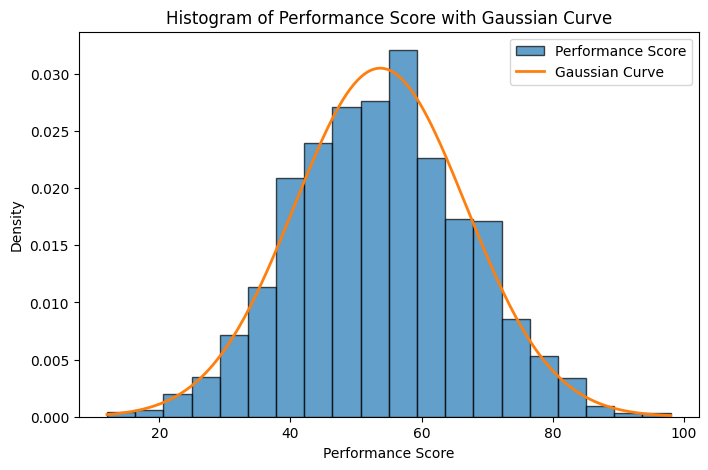

In [8]:

# 1. Histogram with Gaussian Curve
scores = df["Performance_Score"].dropna()

mean_score = scores.mean()
std_score = scores.std()

plt.figure(figsize=(8, 5))

plt.hist(
    scores,
    bins=20,
    density=True,
    edgecolor="black",
    alpha=0.7,
    label="Performance Score"
)

x = np.linspace(scores.min(), scores.max(), 300)

plt.plot(
    x,
    norm.pdf(x, mean_score, std_score),
    linewidth=2,
    label="Gaussian Curve"
)

plt.title("Histogram of Performance Score with Gaussian Curve")
plt.xlabel("Performance Score")
plt.ylabel("Density")
plt.legend()
plt.show()

In [9]:
# 2. Skewness and Kurtosis for Salary
salary = df["Salary"].dropna()

salary_skewness = skew(salary, bias=False)
salary_kurtosis = kurtosis(salary, fisher=True, bias=False)

print("Salary Skewness:", salary_skewness)
print("Salary Excess Kurtosis:", salary_kurtosis)

Salary Skewness: 0.12787956437732742
Salary Excess Kurtosis: -0.15529574387203393


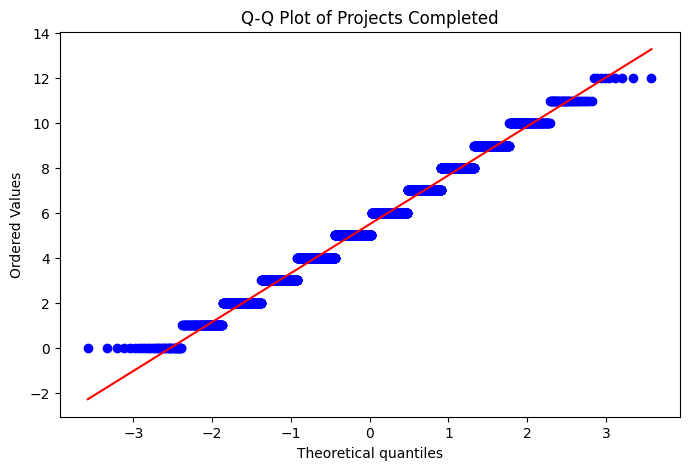

In [10]:
# 3. Q-Q Plot of Projects_Completed
projects = df["Projects_Completed"].dropna()

plt.figure(figsize=(8, 5))

probplot(projects, dist="norm", plot=plt)

plt.title("Q-Q Plot of Projects Completed")
plt.show()

#### Rough Work — Calculations

1. Histogram with Gaussian Curve

Mean = Sum of Performance Scores / Number of Employees

Standard Deviation = Square Root of Variance

The Gaussian curve is plotted using the calculated mean and standard deviation of Performance_Score.

2. Skewness and Kurtosis for Salary

Skewness measures the asymmetry of the salary distribution.

- Skewness = 0: Approximately symmetric distribution.
- Skewness > 0: Positively skewed distribution.
- Skewness < 0: Negatively skewed distribution.

Kurtosis measures the tail heaviness of a distribution relative to a normal distribution.

- Excess Kurtosis = 0: Similar kurtosis to a normal distribution.
- Excess Kurtosis > 0: Heavier tails than a normal distribution.
- Excess Kurtosis < 0: Lighter tails than a normal distribution.

3. Q-Q Plot of Projects_Completed

A Q-Q plot compares the quantiles of Projects_Completed with the quantiles of a theoretical normal distribution.

- Points close to the reference line indicate approximate normality.
- Large deviations from the line indicate departures from normality.

### Conclusion

The histogram visualizes the distribution of Performance_Score with a Gaussian reference curve. Skewness and kurtosis describe the shape of the Salary distribution. The Q-Q plot helps assess whether Projects_Completed approximately follows a normal distribution.

### Step 4: Linear Algebra Application

Take the first 5 employees' [Projects_Completed, Working_Hours] as vectors.

1. Perform dot product between two employee vectors.
2. Find Norm 1 and Norm 2 of an employee's work vector.
3. Compute the angle between two employees' work vectors.

In [11]:
# Take the first 5 employees as vectors
vectors = df[
    ["Projects_Completed", "Working_Hours"]
].head(5).to_numpy(dtype=float)

print("First 5 Employee Vectors:")
print(vectors)

First 5 Employee Vectors:
[[ 5. 49.]
 [ 5. 49.]
 [ 2. 50.]
 [ 5. 46.]
 [ 1. 42.]]


In [12]:
# Select the first two employee vectors
A = vectors[0]
B = vectors[1]

In [13]:
# 1. Dot Product
dot_product = np.dot(A, B)
print("\nDot Product:", dot_product)


Dot Product: 2426.0


In [14]:
# 2. Norm 1 and Norm 2 of Employee A
norm1 = np.linalg.norm(A, ord=1)
norm2 = np.linalg.norm(A, ord=2)

print("Norm 1:", norm1)
print("Norm 2:", norm2)

Norm 1: 54.0
Norm 2: 49.25444142409901


In [15]:
# 3. Angle between two employee vectors
cos_theta = dot_product / (
    np.linalg.norm(A) * np.linalg.norm(B)
)

cos_theta = np.clip(cos_theta, -1, 1)

angle = np.degrees(np.arccos(cos_theta))

print("Angle between vectors:", angle, "degrees")

Angle between vectors: 0.0 degrees


### Conclusion

The dot product measures the combined multiplication of corresponding vector components. Norm 1 and Norm 2 measure the magnitude of an employee's work vector. The angle between two vectors indicates how similar their directions are.